# 06 · NYC Motor Vehicle Collisions – crashes on the Ida night

**Utility for the City Brain: high** · Domain: accidents · Incident types: `accident`

> Every police-reported crash with time, position, injuries and causes; the last link of the flood → traffic signal failure → collisions chain.

| | |
|---|---|
| **Source** | NYC Open Data, Motor Vehicle Collisions – Crashes `h9gi-nx95` |
| **Licence** | NYC Open Data, open |
| **In this repo** | Full extract: `data/accidents/nyc-collisions/collisions_ida.csv` (31 Aug – 3 Sep 2021), `collisions_ref.csv` (August 2021) |
| **Get it** | https://data.cityofnewyork.us/resource/h9gi-nx95.csv |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

One row per crash: `crash_date`, `crash_time`, borough, zip, latitude / longitude, street names, number of persons / pedestrians / cyclists / motorists injured and killed, up to 5 **contributing factors** and vehicle types.

In [2]:
def load(f):
    x = pd.read_csv(path(f'accidents/nyc-collisions/{f}'))
    x['ts'] = pd.to_datetime(x.crash_date.str[:10] + ' ' + x.crash_time)
    return x
ida, ref = load('collisions_ida.csv'), load('collisions_ref.csv')
print(f"Ida extract: {len(ida):,} crashes · August reference: {len(ref):,} crashes over {ref.ts.dt.date.nunique()} days")
ida[['ts', 'borough', 'latitude', 'longitude', 'number_of_persons_injured', 'contributing_factor_vehicle_1']].head()

Ida extract: 1,347 crashes · August reference: 9,880 crashes over 31 days


,ts,borough,latitude,longitude,number_of_persons_injured,contributing_factor_vehicle_1
0,2021-08-31 05:25:00,NaN,40.603493,-74.067345,0,Unsafe Lane Changing
1,2021-08-31 15:15:00,NaN,40.695200,-73.928440,1,Driver Inattention/Distraction
2,2021-08-31 19:00:00,QUEENS,40.757706,-73.941270,0,Unspecified
3,2021-08-31 17:20:00,QUEENS,40.767727,-73.919820,0,Driver Inattention/Distraction
4,2021-08-31 08:36:00,QUEENS,40.779250,-73.913890,0,Passing or Lane Usage Improper


## 2. Did the storm change crash numbers?

Crashes 1 Sep 18:00 – 2 Sep 06:00: 160 vs a typical 135 (+19 %)


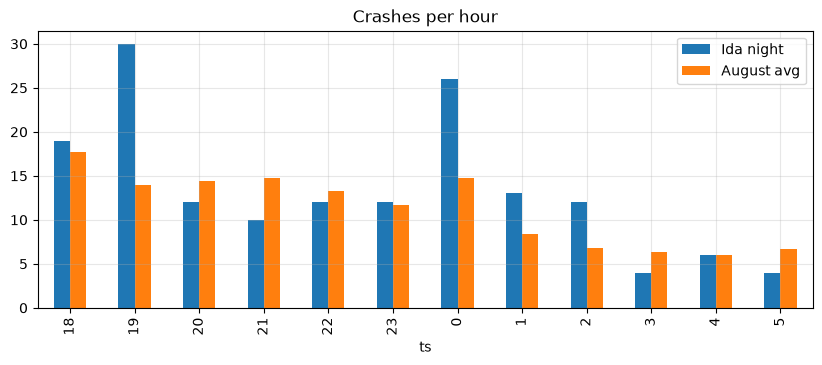

In [3]:
win = ida[(ida.ts >= '2021-09-01 18:00') & (ida.ts < '2021-09-02 06:00')]
ref_h = ref.groupby(ref.ts.dt.hour).size() / ref.ts.dt.date.nunique()
typ12 = ref_h.loc[list(range(18, 24)) + list(range(0, 6))].sum()
print(f"Crashes 1 Sep 18:00 – 2 Sep 06:00: {len(win)} vs a typical {typ12:.0f} (+{(len(win) / typ12 - 1) * 100:.0f} %)")
ih = win.groupby(win.ts.dt.hour).size()
order = list(range(18, 24)) + list(range(0, 6))
pd.DataFrame({'Ida night': ih.reindex(order), 'August avg': ref_h.reindex(order).round(1)}).plot(kind='bar', title='Crashes per hour'); plt.show()

In [4]:
f = pd.concat([win[c] for c in win.columns if c.startswith('contributing_factor')]).dropna()
f[f != 'Unspecified'].value_counts().head(8).to_frame('Ida night factors')

,Ida night factors
Driver Inattention/Distraction,34
Failure to Yield Right-of-Way,16
Pavement Slippery,14
Other Vehicular,10
Following Too Closely,8
Unsafe Speed,6
Backing Unsafely,6
Traffic Control Disregarded,6


## 3. What it means for the City Brain

| Use | How |
|---|---|
| **Scenarios** | The end of the Storm-night chain: flood → signal failures (notebook 05) → more crashes (about +20 % over the night, "pavement slippery" among causes) |
| **Graph** | Crashes have positions: link them to zones and to the flood incident nearby (`/chain`) |
| **Mock** | Real accident calls / reports at real positions and rates |

**Limits:** police-reported crashes only; the effect of the storm is moderate (many people stayed home); no sensor data.